# GIAI ĐOẠN 1 – FP-GROWTH

Notebook này gồm:
1. FP-Growth tự cài đặt (cây FP-tree) và đối chiếu với mlxtend.fpgrowth.
2. Chạy lưới 5 support × 4 confidence giống hệt notebook Apriori, trên cùng file dữ liệu.
3. So sánh thời gian thật của Apriori và FP-Growth (cả bản tự cài đặt lẫn mlxtend), đo cùng một cách: 1 lần khởi động, lấy trung vị của 3 lần chạy.
4. Xuất luật của cấu hình được chọn và hàm gợi ý mua kèm.


## 1. Cấu hình và thư viện

In [6]:
import hashlib, json, subprocess, sys, time
from collections import Counter
from decimal import Decimal, ROUND_CEILING
from fractions import Fraction
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mlxtend  # noqa: F401
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlxtend"])
from mlxtend.frequent_patterns import apriori as mlx_apriori, fpgrowth as mlx_fpgrowth
from mlxtend.preprocessing import TransactionEncoder

sys.setrecursionlimit(10000)

# ===== CẤU HÌNH (giữ giống notebook Apriori) =====
DATA_CANDIDATES = [Path("customers_clean_apriori.csv"),
                   Path("sample_data/customers_clean_apriori.csv"),
                   Path("data/processed/customers_clean_apriori.csv")]
OUT_DIR = Path("results")
SUPPORTS = [0.001, 0.003, 0.005, 0.0075, 0.010]
CONFS = [0.08, 0.10, 0.12, 0.15]
SO_LAN = 3
S_CHON, C_CHON = 0.001, 0.08
MIN_GIO_TIN_CAY = 30
HASH_THAM_CHIEU = "7910a17405595931e73ac896e71ba1256b1d4b2596f6f5350e7535ce77c99137"

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 2. Đọc dữ liệu và tạo giỏ hàng

In [7]:
def tim_file():
    for p in DATA_CANDIDATES:
        if p.exists():
            return p
    for mau in ["*customers_clean_apriori*.csv", "*Groceries_cleaned*.csv", "*customers_clean*.csv"]:
        khop = sorted(Path(".").rglob(mau))
        if khop:
            return khop[0]
    try:
        from google.colab import files
        up = files.upload()
        if not up:
            raise FileNotFoundError("Bạn chưa chọn file nào.")
        return Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError("Không thấy file dữ liệu. Đặt customers_clean_apriori.csv cạnh notebook.")


def doc_du_lieu(path):
    df = pd.read_csv(path)
    thieu = {"Member_number", "Date", "itemDescription"} - set(df.columns)
    if thieu:
        raise ValueError(f"Thiếu cột: {sorted(thieu)}. Các cột hiện có: {list(df.columns)}")
    d = df["Date"].astype(str).str.strip()
    la_iso = d.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
    ngay = pd.to_datetime(d.where(la_iso), format="%Y-%m-%d", errors="coerce")
    ngay = ngay.fillna(pd.to_datetime(d.where(~la_iso), format="%d-%m-%Y", errors="coerce"))
    if ngay.isna().any():
        raise ValueError(f"Có {int(ngay.isna().sum())} ngày không đọc được.")
    df["Date"] = ngay
    df["itemDescription"] = df["itemDescription"].astype(str).str.strip().str.lower()
    return df


def tao_giao_dich(df):
    grouped = df.groupby(["Member_number", "Date"], sort=True)["itemDescription"].agg(list)
    return [tuple(sorted(set(b))) for b in grouped]


file_dl = tim_file()
df = doc_du_lieu(file_dl)
transactions = tao_giao_dich(df)
N = len(transactions)
items = sorted(set().union(*map(set, transactions)))
sha = hashlib.sha256(json.dumps(transactions, ensure_ascii=False,
                                separators=(",", ":")).encode()).hexdigest()

print(f"File: {file_dl} | {len(df):,} dòng")
print(f"Giỏ hàng: {N:,} | Mặt hàng: {len(items)} | "
      f"TB mặt hàng/giỏ: {np.mean([len(t) for t in transactions]):.2f} | "
      f"Lớn nhất: {max(len(t) for t in transactions)}")
print("SHA-256 giỏ hàng:", sha)
print("Khớp mã tham chiếu của nhóm:", sha == HASH_THAM_CHIEU)
if len(df) != 38006:
    print("CẢNH BÁO: báo cáo ghi 38.006 dòng, file này có", len(df), "dòng.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

File: sample_data/customers_clean_apriori.csv | 38,006 dòng
Giỏ hàng: 14,963 | Mặt hàng: 167 | TB mặt hàng/giỏ: 2.54 | Lớn nhất: 10
SHA-256 giỏ hàng: 9e488b9d94da22ee83b3e6e743f8b1b0a5f691f6cac26d704c721cf4045f6505
Khớp mã tham chiếu của nhóm: False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 3. Cài đặt thuật toán
- **FP-Growth tự cài đặt:** đếm mặt hàng, xây cây FP-tree theo thứ tự tần suất giảm dần, rồi với mỗi mặt hàng lấy *cơ sở mẫu có điều kiện* (các đường đi dẫn tới nó) để xây cây điều kiện và đệ quy. Không sinh tập ứng viên.
- **Apriori tự cài đặt:** giữ lại để so sánh thời gian cùng trong một notebook.
- **Sinh luật** dùng chung cho cả hai (so sánh confidence bằng phân số chính xác).

In [8]:
def min_count(support, n):
    """Số giỏ tối thiểu = ceil(support * n), tính bằng Decimal để tránh sai số số thực."""
    return int((Decimal(str(support)) * n).to_integral_value(rounding=ROUND_CEILING))


class NutFP:
    __slots__ = ("item", "count", "parent", "children")

    def __init__(self, item, parent):
        self.item, self.count, self.parent, self.children = item, 0, parent, {}


def xay_fp_tree(du_lieu, min_c):
    """du_lieu: danh sách (danh sách mặt hàng, trọng số). Trả về (bảng header, mặt hàng phổ biến)."""
    dem = Counter()
    for mat_hang, w in du_lieu:
        for i in mat_hang:
            dem[i] += w
    pho_bien = {i: c for i, c in dem.items() if c >= min_c}
    if not pho_bien:
        return None, pho_bien
    thu_tu = {i: r for r, (i, _) in enumerate(sorted(pho_bien.items(), key=lambda x: (-x[1], x[0])))}
    goc = NutFP(None, None)
    header = {i: [] for i in pho_bien}
    for mat_hang, w in du_lieu:
        loc = sorted((i for i in mat_hang if i in pho_bien), key=thu_tu.__getitem__)
        nut = goc
        for i in loc:
            con = nut.children.get(i)
            if con is None:
                con = NutFP(i, nut)
                nut.children[i] = con
                header[i].append(con)
            con.count += w
            nut = con
    return header, pho_bien


def fp_growth_tu_cai_dat(transactions, min_support):
    """Trả về {frozenset(tập mặt hàng): số giỏ chứa tập đó}."""
    n = len(transactions)
    min_c = min_count(min_support, n)
    ket_qua = {}

    def khai_thac(du_lieu, hau_to):
        header, pho_bien = xay_fp_tree(du_lieu, min_c)
        if not header:
            return
        for item, c in pho_bien.items():
            moi = hau_to | {item}
            ket_qua[moi] = c
            co_so = []                     # cơ sở mẫu có điều kiện của `item`
            for nut in header[item]:
                duong, p = [], nut.parent
                while p is not None and p.item is not None:
                    duong.append(p.item)
                    p = p.parent
                if duong:
                    co_so.append((duong[::-1], nut.count))
            if co_so:
                khai_thac(co_so, moi)

    khai_thac([(t, 1) for t in transactions], frozenset())
    return ket_qua


def apriori_tu_cai_dat(transactions, min_support):
    n = len(transactions)
    nguong = min_count(min_support, n)
    dem = Counter(item for t in transactions for item in t)
    L = {frozenset([i]): c for i, c in dem.items() if c >= nguong}
    ket_qua = dict(L)
    k = 2
    while L:
        truoc = set(L)
        ung_vien = {}
        for a in truoc:
            for b in truoc:
                u = a | b
                if len(u) == k and u not in ung_vien:
                    if all(frozenset(s) in truoc for s in combinations(u, k - 1)):
                        ung_vien[u] = 0
        if not ung_vien:
            break
        for t in transactions:
            if len(t) >= k:
                for c in combinations(t, k):
                    fs = frozenset(c)
                    if fs in ung_vien:
                        ung_vien[fs] += 1
        L = {s: c for s, c in ung_vien.items() if c >= nguong}
        ket_qua.update(L)
        k += 1
    return ket_qua


COT_LUAT = ["antecedents", "consequents", "so_gio", "support", "confidence", "lift"]


def sinh_luat(freq, min_conf, n):
    nguong = Fraction(str(min_conf))
    rows = []
    for itemset, c in freq.items():
        if len(itemset) < 2:
            continue
        for k in range(1, len(itemset)):
            for trai in combinations(sorted(itemset), k):
                trai = frozenset(trai)
                phai = itemset - trai
                c_trai, c_phai = freq[trai], freq[phai]
                if Fraction(c, c_trai) >= nguong:
                    rows.append({"antecedents": trai, "consequents": phai, "so_gio": c,
                                 "support": c / n, "confidence": c / c_trai,
                                 "lift": c * n / (c_trai * c_phai)})
    return pd.DataFrame(rows, columns=COT_LUAT)


def loc_luat_thua(rules):
    """Loại luật có luật tổng quát hơn (vế trái là tập con thực sự, cùng vế phải) với confidence không thấp hơn."""
    if rules.empty:
        return rules.copy()
    theo_ve_phai = {}
    for r in rules.itertuples():
        theo_ve_phai.setdefault(r.consequents, []).append((r.antecedents, r.confidence))
    giu = [not any(a < r.antecedents and conf >= r.confidence
                   for a, conf in theo_ve_phai[r.consequents])
           for r in rules.itertuples()]
    return rules[giu].copy()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 4. Kiểm tra tính đúng đắn
FP-Growth tự cài đặt phải cho đúng cùng tập phổ biến và cùng số đếm với: Apriori tự cài đặt, phép đếm trực tiếp, và mlxtend (cả fpgrowth lẫn apriori).

In [9]:
te = TransactionEncoder()
df_enc = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print("Ma trận mã hóa:", df_enc.shape)


def doi_chieu_mlxtend(freq, fi):
    mlx = {frozenset(s): sup for s, sup in zip(fi["itemsets"], fi["support"])}
    if set(mlx) != set(freq):
        return False
    return all(np.isclose(sup, freq[s] / N) for s, sup in mlx.items())


freq_fp = {s: fp_growth_tu_cai_dat(transactions, s) for s in SUPPORTS}
freq_ap = {s: apriori_tu_cai_dat(transactions, s) for s in SUPPORTS}

# 1) FP-Growth tự cài đặt == Apriori tự cài đặt (cùng tập, cùng số đếm)
for s in SUPPORTS:
    assert freq_fp[s] == freq_ap[s], f"FP-Growth lệch Apriori ở support={s}"

# 2) Đếm trực tiếp mọi tổ hợp xuất hiện, độc lập với cả hai thuật toán
max_k = max(len(x) for f in freq_fp.values() for x in f)
quan_sat = Counter()
for t in transactions:
    for k in range(1, min(len(t), max_k) + 1):
        quan_sat.update(frozenset(c) for c in combinations(t, k))
for s, f in freq_fp.items():
    mong_doi = {x: c for x, c in quan_sat.items() if c >= min_count(s, N)}
    assert f == mong_doi, f"FP-Growth lệch phép đếm trực tiếp ở support={s}"

# 3) Tính bao hàm giữa các ngưỡng
ds = sorted(SUPPORTS)
for a, b in zip(ds, ds[1:]):
    assert set(freq_fp[b]) <= set(freq_fp[a])
print("PASS: FP-Growth tự cài đặt khớp Apriori tự cài đặt và phép đếm trực tiếp ở mọi ngưỡng.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ma trận mã hóa: (14963, 167)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

PASS: FP-Growth tự cài đặt khớp Apriori tự cài đặt và phép đếm trực tiếp ở mọi ngưỡng.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 5. Thực nghiệm lưới support × confidence và so sánh thời gian
Mỗi phương pháp chạy 1 lần khởi động (không tính), sau đó đo 3 lần và lấy **trung vị**. Bốn cách được so sánh: Apriori và FP-Growth tự cài đặt (đầu vào là danh sách giỏ), `mlxtend.apriori` và `mlxtend.fpgrowth` (đầu vào là ma trận one-hot).

In [5]:
def do_thoi_gian(ham, *args, lan=SO_LAN):
    ham(*args)
    ts = []
    for _ in range(lan):
        t0 = time.perf_counter()
        ham(*args)
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


def mlx_ap(s):
    return mlx_apriori(df_enc, min_support=s, use_colnames=True)


def mlx_fp(s):
    return mlx_fpgrowth(df_enc, min_support=s, use_colnames=True)


rows = []
for s in SUPPORTS:
    freq = freq_fp[s]
    t_ap = do_thoi_gian(apriori_tu_cai_dat, transactions, s)
    t_fp = do_thoi_gian(fp_growth_tu_cai_dat, transactions, s)
    t_mlx_ap = do_thoi_gian(mlx_ap, s)
    t_mlx_fp = do_thoi_gian(mlx_fp, s)
    khop = doi_chieu_mlxtend(freq, mlx_fp(s)) and doi_chieu_mlxtend(freq, mlx_ap(s))
    for c in CONFS:
        luat = sinh_luat(freq, c, N)
        rows.append({"min_support": s, "min_conf": c,
                     "so_gio_toi_thieu": min_count(s, N),
                     "so_tap_pho_bien": len(freq),
                     "so_luat": len(luat),
                     "so_luat_lift_gt_1": int((luat["lift"] > 1).sum()),
                     "tg_apriori_tu_cai_dat_s": round(t_ap, 4),
                     "tg_fpgrowth_tu_cai_dat_s": round(t_fp, 4),
                     "tg_mlxtend_apriori_s": round(t_mlx_ap, 4),
                     "tg_mlxtend_fpgrowth_s": round(t_mlx_fp, 4),
                     "khop_mlxtend": khop})
bang = pd.DataFrame(rows)
assert bang["khop_mlxtend"].all(), "Có ngưỡng mà kết quả không khớp mlxtend"
print("PASS: tập phổ biến và support khớp mlxtend (apriori và fpgrowth) ở mọi ngưỡng.\n")

thoi_gian = (bang.drop_duplicates("min_support")
             [["min_support", "so_tap_pho_bien", "tg_apriori_tu_cai_dat_s", "tg_fpgrowth_tu_cai_dat_s",
               "tg_mlxtend_apriori_s", "tg_mlxtend_fpgrowth_s"]])
display(thoi_gian.reset_index(drop=True))

Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().

PASS: tập phổ biến và support khớp mlxtend (apriori và fpgrowth) ở mọi ngưỡng.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,min_support,so_tap_pho_bien,tg_apriori_tu_cai_dat_s,tg_fpgrowth_tu_cai_dat_s,tg_mlxtend_apriori_s,tg_mlxtend_fpgrowth_s
0,0.0010,750,0.2521,0.1910,4.2324,61.3220
1,0.0030,216,0.1386,0.1333,1.1965,10.5729
2,0.0050,126,0.1715,0.3253,0.6328,4.1559
3,0.0075,86,0.1190,0.1193,0.4605,1.4671
4,0.0100,69,0.1022,0.1243,0.3275,0.7627


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Số luật theo từng cặp ngưỡng (kết quả của hai thuật toán là như nhau vì cùng tập phổ biến):

In [10]:
print("Số luật đạt support và confidence:")
display(bang.pivot(index="min_support", columns="min_conf", values="so_luat"))
print("Trong đó, số luật có lift > 1:")
display(bang.pivot(index="min_support", columns="min_conf", values="so_luat_lift_gt_1"))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Số luật đạt support và confidence:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


min_conf,0.08,0.10,0.12,0.15
min_support,,,,
0.0010,231,131,73,10
0.0030,79,39,26,1
0.0050,35,19,16,1
0.0075,15,7,5,0
0.0100,8,4,3,0


Trong đó, số luật có lift > 1:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


min_conf,0.08,0.10,0.12,0.15
min_support,,,,
0.0010,54,37,23,8
0.0030,5,2,1,0
0.0050,3,1,1,0
0.0075,0,0,0,0
0.0100,0,0,0,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

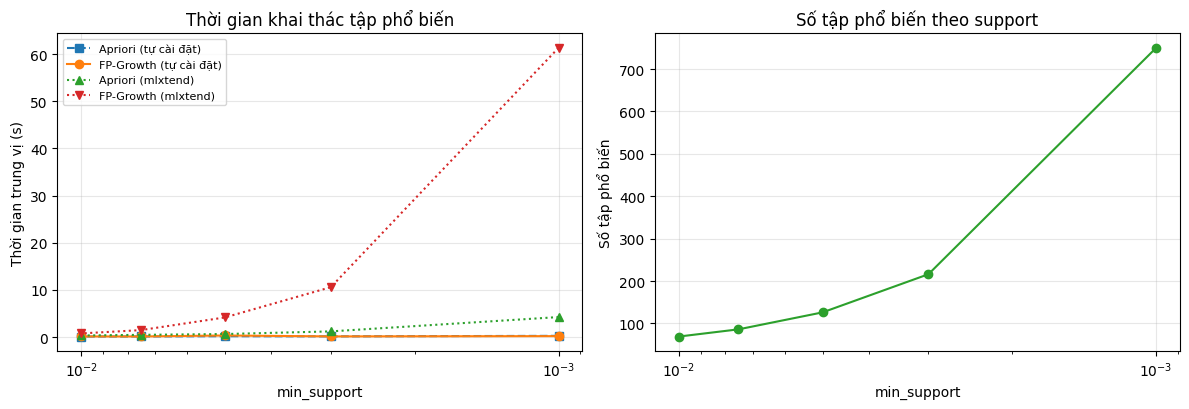

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
OUT_DIR.mkdir(exist_ok=True)
bang.to_csv(OUT_DIR / "so_sanh_apriori_fpgrowth.csv", index=False)

g = bang.drop_duplicates("min_support").sort_values("min_support")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(g["min_support"], g["tg_apriori_tu_cai_dat_s"], "s--", label="Apriori (tự cài đặt)")
ax[0].plot(g["min_support"], g["tg_fpgrowth_tu_cai_dat_s"], "o-", label="FP-Growth (tự cài đặt)")
ax[0].plot(g["min_support"], g["tg_mlxtend_apriori_s"], "^:", label="Apriori (mlxtend)")
ax[0].plot(g["min_support"], g["tg_mlxtend_fpgrowth_s"], "v:", label="FP-Growth (mlxtend)")
ax[0].set(xscale="log", xlabel="min_support", ylabel="Thời gian trung vị (s)",
          title="Thời gian khai thác tập phổ biến")
ax[0].legend(fontsize=8)
ax[1].plot(g["min_support"], g["so_tap_pho_bien"], "o-", color="tab:green")
ax[1].set(xscale="log", xlabel="min_support", ylabel="Số tập phổ biến",
          title="Số tập phổ biến theo support")
for a in ax:
    a.invert_xaxis()
    a.grid(alpha=.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "so_sanh_thoi_gian.png", dpi=150)
plt.show()

## 6. Luật của cấu hình được chọn
Quy trình: sinh luật từ tập phổ biến do FP-Growth tìm được → giữ luật có lift > 1 → loại luật thừa. `so_gio` là số giỏ chứa cả hai vế; luật có `so_gio` nhỏ chỉ nên xem là gợi ý tham khảo.

In [12]:
tat_ca = sinh_luat(freq_fp[S_CHON], C_CHON, N)
lift_duong = tat_ca[tat_ca["lift"] > 1]
sach = loc_luat_thua(tat_ca)
sach = sach[sach["lift"] > 1].copy()
sach["du_tin_cay"] = sach["so_gio"] >= MIN_GIO_TIN_CAY

print(f"Cấu hình: support={S_CHON}, confidence={C_CHON}")
print(f"  Luật đạt ngưỡng:                  {len(tat_ca)}")
print(f"  Luật có lift > 1:                 {len(lift_duong)}")
print(f"  Sau khi loại luật thừa:           {len(sach)}")
print(f"  Trong đó có so_gio >= {MIN_GIO_TIN_CAY}:           {int(sach['du_tin_cay'].sum())}")

cach = lambda x: ", ".join(sorted(x))
xuat = sach.assign(antecedents=sach["antecedents"].map(cach),
                   consequents=sach["consequents"].map(cach))
xuat = xuat.sort_values(["lift", "confidence"], ascending=False)
xuat.to_csv(OUT_DIR / "fpgrowth_luat.csv", index=False)
display(xuat.head(15).round(4))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cấu hình: support=0.001, confidence=0.08
  Luật đạt ngưỡng:                  231
  Luật có lift > 1:                 54
  Sau khi loại luật thừa:           54
  Trong đó có so_gio >= 30:           11


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,so_gio,support,confidence,lift,du_tin_cay
9,"whole milk, yogurt",sausage,22,0.0015,0.1317,2.1829,False
7,"sausage, whole milk",yogurt,22,0.0015,0.1642,1.9118,False
92,specialty chocolate,citrus fruit,21,0.0014,0.0879,1.6538,False
8,"sausage, yogurt",whole milk,22,0.0015,0.2558,1.6199,False
128,flour,tropical fruit,16,0.0011,0.1096,1.6171,False
197,beverages,sausage,23,0.0015,0.0927,1.5368,False
17,"soda, whole milk",sausage,16,0.0011,0.0920,1.5237,False
175,processed cheese,root vegetables,16,0.0011,0.1053,1.5130,False
190,soft cheese,yogurt,19,0.0013,0.1267,1.4750,False
72,curd,sausage,44,0.0029,0.0873,1.4466,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 7. Gợi ý mua kèm (dùng cho demo)

In [13]:
def goi_y(san_pham, luat, top_n=5):
    """Sản phẩm nên mua kèm khi khách chọn `san_pham`, xếp theo lift rồi confidence."""
    sp = san_pham.strip().lower()
    khop = luat[luat["antecedents"].map(lambda a: a == frozenset([sp]))]
    if khop.empty:
        return f"Chưa có luật mua kèm cho '{sp}' ở cấu hình hiện tại."
    khop = khop.sort_values(["lift", "confidence"], ascending=False)
    khop = khop.assign(goi_y=khop["consequents"].map(cach))
    return khop[["goi_y", "so_gio", "confidence", "lift"]].head(top_n).round(4)


mau = sorted({next(iter(a)) for a in sach["antecedents"] if len(a) == 1})[:3]
for sp in mau:
    print(f"Khách chọn: {sp}")
    display(goi_y(sp, sach))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Khách chọn: berries


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,goi_y,so_gio,confidence,lift
201,other vegetables,40,0.1227,1.0049


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Khách chọn: cat food


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,goi_y,so_gio,confidence,lift
223,tropical fruit,15,0.0847,1.2505


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 8. Tải kết quả (chỉ chạy trên Colab)

In [14]:
try:
    from google.colab import files
    for f in ["so_sanh_apriori_fpgrowth.csv", "fpgrowth_luat.csv", "so_sanh_thoi_gian.png"]:
        files.download(str(OUT_DIR / f))
except ImportError:
    print("Không chạy trên Colab: file nằm trong thư mục", OUT_DIR.resolve())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag